In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error
from scipy.optimize import minimize_scalar

In [2]:
df = pd.read_csv('cleaned data.csv')
df.head()

,variable 1,variable 2,Output
0,30,30,2315.7
1,30,35,1932.6
2,30,40,1592.2
3,30,45,1316.6
4,30,50,1099.5


In [3]:
X = df.drop(columns = ['Output']).iloc[:25]
X2 = df['variable 2'].iloc[:25].to_numpy()
X1 = df['variable 2'].iloc[:25].to_numpy().reshape(-1,1)
Y = df['Output'].iloc[:25].to_numpy()

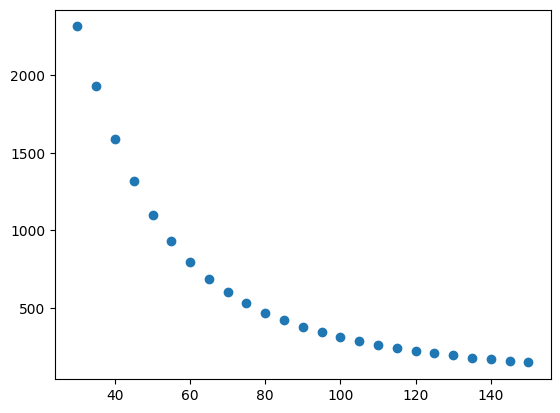

In [4]:
plt.scatter(X1,Y)

In [5]:
# def J(b):
#     z = Y-b
#     if np.any(z <= 0):
#         return np.inf
#     tempmodel = LinearRegression()
#     tempmodel.fit(X1,np.log(z))
#     return mean_squared_error(np.log(z),tempmodel.predict(X1))


def J(b):
    z = Y-b
    if np.any(z <= 0):
        return np.inf
    k, intercept = np.polyfit(X2,np.log(z),1)
    Ypred2 = np.exp(k*X2+intercept) + b
    return np.sum((Y-Ypred2)**2)

In [6]:
np.polyfit(X2,Y,1)

array([ -13.91967538, 1884.82758462])

In [7]:
X2

array([ 30,  35,  40,  45,  50,  55,  60,  65,  70,  75,  80,  85,  90,
        95, 100, 105, 110, 115, 120, 125, 130, 135, 140, 145, 150],
      dtype=int64)

In [8]:
b_upper = np.min(Y) - 1e-9

In [9]:
res = minimize_scalar(J, bounds = (-1e6, b_upper), method = 'bounded')
res.x,res.fun

(131.47352016984786, 19186.552431842883)

In [10]:
res.success

True

In [11]:
res.x

131.47352016984786

Analysis

In [12]:
# model = LinearRegression()
# model.fit(X1,np.log(Y))
# Ypred = np.exp(model.predict(X1))

In [13]:
m1,b1 = np.polyfit(X2,np.log(Y),1)
Ypred1 = np.exp(m1*X2+b1)

In [14]:
# model1 = LinearRegression()
# model1.fit(X1,np.log(Y-res.x))
# Ypred1 = np.exp(model1.predict(X1))+res.x

In [15]:
m2,b2 = np.polyfit(X2,np.log(Y-res.x),1)
Ypred2 = np.exp(m2*X2+b2) + res.x

In [16]:
X11 = X1.flatten()

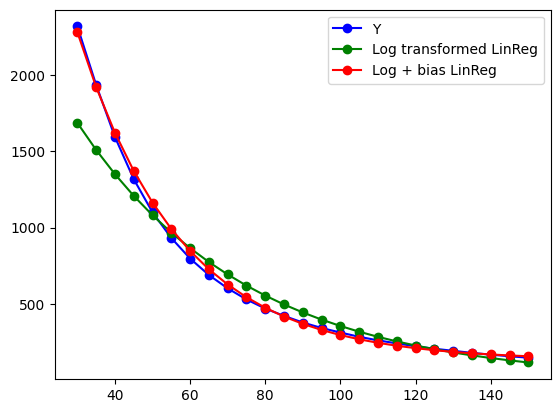

In [17]:
plt.plot(X11,Y,c = 'b', label = 'Y',marker = 'o')
plt.plot(X11,Ypred1,c = 'g', label = 'Log transformed LinReg',marker = 'o')
plt.plot(X11,Ypred2,c = 'r', label = 'Log + bias LinReg',marker = 'o')
plt.legend()

In [18]:
print('MSE for Log transformed LinReg: ',mean_squared_error(Y,Ypred1))
print('MSE for Log + bias LinReg: ',mean_squared_error(Y,Ypred2))

MSE for Log transformed LinReg:  28241.094492180193
MSE for Log + bias LinReg:  767.4620972737154
